# Llegir les dades


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
dataset_csv = pd.read_csv(r"../../Speculation-Map/Data/TouristicRentals/TouristicRentals.csv",
                       index_col=0,dtype=object)

dataset_csv

,Número inscripció,Dígit de control,Rètol,Estat,Tipus de via,Nom de la via,Número,Pis,Porta,Escala,...,Unitat d'allotjament,Total places,Total estances,SSTT,Marca turística,CIF,Raó Social del titular,Nom del titular,Primer cognom,Segon cognom
Tipus establiment,,,,,,,,,,,,,,,,,,,,,
Autocaravanes,AAG-000002,4,ÀREA MASSÍS DEL MONTGRÍ CAMPER PARK,Alta,Carrer,del Camí Vell d'Ullà,21,NaN,NaN,NaN,...,Parcel·les,30,NaN,Girona,Costa Brava,B55091011,"MASSÍS DEL MONTGRÍ, S.L.",No aplica,No aplica,No aplica
Autocaravanes,AAG-000006,8,AUTOCARAVANING PALAMOS,Alta,Ronda,DE L'EST,SN,NaN,NaN,NaN,...,Parcel·les,66,NaN,Girona,Costa Brava,B55200927,AUTOCARAVANING PALAMOS S.L.,No aplica,No aplica,No aplica
Autocaravanes,AAG-000011,53,AUTOCARAVANING VILAROMA,Alta,Passatge,VILAROMÀ,45,NaN,NaN,NaN,...,Parcel·les,44,NaN,Girona,Costa Brava,B13795935,PARATGE VILAROMA S.L.,No aplica,No aplica,No aplica
Autocaravanes,AAG-000013,59,Autocaravaning Empuriabrava,Alta,Polígon,El poliol 5,21,NaN,NaN,NaN,...,Parcel·les,57,NaN,Girona,Costa Brava,B75783050,AUTOCARAVANING EMPURIABRAVA SL,No aplica,No aplica,No aplica
Autocaravanes,AAL-000009,91,Prat del Salt Camper Park Pallars,Alta,Carretera,C-28z,s/n,NaN,NaN,NaN,...,Parcel·les,25,NaN,Lleida,Pirineus,No aplica,No aplica,Júlia,Serra,Izquierdo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Turisme rural,PVA-000641,75,CASA CHIN,Alta,Carrer,Major,32,NaN,NaN,NaN,...,Allotjament sencer,12,5,Vall d'Aran,Val d'Aran,No aplica,No aplica,JORDI,ARJÓ,FRANCÉS
Turisme rural,PVA-001015,93,TORISME RURAU CASA REY,Alta,Carrer,SASPLAS,6,NaN,NaN,NaN,...,Allotjament sencer,12,5,Vall d'Aran,Val d'Aran,No aplica,No aplica,Carmen,Castellarnau,Lafont
Turisme rural,PVA-001379,85,ES DE PAU AGROTURISME,Alta,Carrer,Sant Esteve,9,NaN,NaN,NaN,...,Allotjament sencer,5,3,Vall d'Aran,Val d'Aran,No aplica,No aplica,Jose Maria,Moga,Cortinat


# Comptar allotjaments turístics per codi de municipi

In [13]:
conteo_municipios = (
    dataset_csv["Codi Municipi (IDESCAT)"]
    .value_counts()
    .reset_index()
)
conteo_municipios.columns = ["Codi Municipi (IDESCAT)", "NombreEdificis"]


conteo_municipios.rename(columns={"Codi Municipi (IDESCAT)": "CODIMUNI"},inplace=True)
print(conteo_municipios)

    CODIMUNI  NombreEdificis
0     080193           11420
1     439057            7204
2     171523            5401
3     430385            3804
4     170470            3690
..       ...             ...
917   250740               1
918   251919               1
919   250411               1
920   250851               1
921   430347               1

[922 rows x 2 columns]


C:\Users\user\AppData\Local\Temp\ipykernel_20656\2903630879.py:9: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  conteo_municipios.rename(columns={"Codi Municipi (IDESCAT)": "CODIMUNI"},inplace=True)


# Merge del mapa amb el compteig d'habitatges

In [14]:
municipis=gpd.read_file("../../Speculation-Map/Data/CatalunyaMapMunicipalities.json").to_crs(25831)
municipis = municipis.merge(conteo_municipios, on="CODIMUNI", how="left", validate="one_to_one")

In [15]:
municipis

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,NombreEdificis
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",7.0
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",5.0
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",149.0
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",15.0
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",31.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,439039,Camarles,Camarles,30.0157,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((301288.757 4521580.722, 301179...",64.0
943,439044,l'Aldea,l'Aldea,30.4743,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((298373.126 4520080.954, 298283...",31.0
944,439057,Salou,Salou,15.1248,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,43,Tarragona,Tarragona,"MULTIPOLYGON (((343971.449 4551180.512, 343522...",7204.0
945,439060,l'Ampolla,l'Ampolla,35.6196,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((305434.379 4524718.838, 305365...",688.0


# Mapa d'habitatges per municipi

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

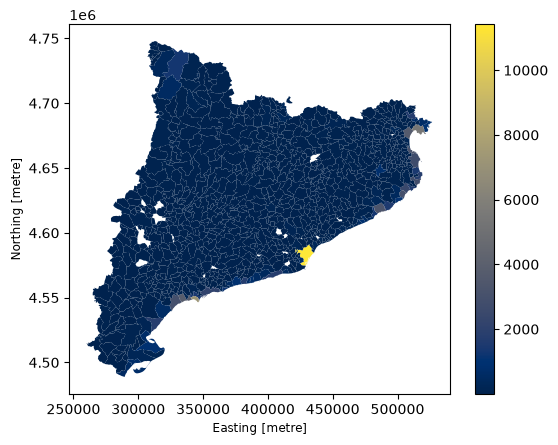

In [16]:

municipis.plot(column="NombreEdificis", cmap="cividis", legend=True)


# Llegir el dataset d'habitants

In [17]:
habitants = gpd.read_file("../../Speculation-Map/Data/Habitants.csv")
habitants


,YEAR,MUN,SEX,CONCEPT,status,value
0,2025,250019,M,POP,,83
1,2025,250019,F,POP,,79
2,2025,250019,TOTAL,POP,,162
3,2025,080018,M,POP,,6634
4,2025,080018,F,POP,,6573
...,...,...,...,...,...,...
2866,2025,430521,F,POP,,602
2867,2025,430521,TOTAL,POP,,1186
2868,2025,TOTAL,M,POP,,4006834
2869,2025,TOTAL,F,POP,,4117292


# Reordenem la taula i fem una copia del codi de municipi per a que no sigui un index, sino una columna

In [18]:
habitants1 = habitants_csv.pivot(index="MUN",columns="SEX",values="value")
habitants1["MUN_COPY"] = habitants1.index
habitants1

NameError: name 'habitants_csv' is not defined

# Fem que la columna de codi de municipi es digui igual que la del merge anterior

In [ ]:
habitants1.rename(columns={"MUN_COPY": "CODIMUNI"},inplace=True)
habitants1

# Afegim la columna d'habitants a la llista

In [ ]:
municipis_merged = municipis.merge(habitants1, on="CODIMUNI", how="left", validate="one_to_one")
municipis_merged

In [ ]:
municipis_merged["TOTAL"]=pd.to_numeric(municipis_merged["TOTAL"], errors="coerce") #Ha calgut passar de string a float la columna TOTAL

# Creem una nova columna que sigui la fracció entre Habitatges/Habitants

In [ ]:
municipis_merged["fraccio"] = municipis_merged["NombreEdificis"]/municipis_merged["TOTAL"]
municipis_merged

# Plotejem el mapa en funció de la columna fracció (afegim escala i orientació)

In [ ]:
def add_scale_bar(ax, length_km=50, loc=(0.05, 0.002)):
    """Draw a scale bar of length_km on an Axes whose coordinates are in metres."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + loc[0] * (x1 - x0)
    y = y0 + loc[1] * (y1 - y0)
    ax.plot([x, x + length_km * 1000], [y, y], color="black", lw=3)
    ax.text(x + length_km * 500, y + 0.015 * (y1 - y0), f"{length_km} km", ha="center", va="bottom", fontsize=9)


def add_north_arrow(ax, loc=(0.93, 0.93)):
    ax.annotate("N", xy=loc, xytext=(loc[0], loc[1] - 0.1), xycoords="axes fraction",
                ha="center", va="center", fontsize=12, fontweight="bold",
                arrowprops={"arrowstyle": "-|>", "color": "black"})

In [ ]:
from matplotlib.colors import LogNorm # En escala logarítmica
fig, axs = plt.subplots(1, 1, figsize=(11, 5))
municipis_merged.plot(column="fraccio", cmap="cividis", norm=LogNorm(),legend=True, ax=axs,
         legend_kwds={"shrink": 0.7})
axs.set_title("Habitatges turístics/habitants")
axs.set_axis_off()
add_scale_bar(axs)
add_north_arrow(axs)
plt.show()

# Plotejem per quintils

In [ ]:
municipis_merged["quintile"] = pd.qcut(municipis_merged["fraccio"], 5, labels=["lowest 20%", "2", "3", "4", "highest 20%"])

In [ ]:
from matplotlib.colors import LogNorm
fig, axs = plt.subplots(1, 1, figsize=(11, 5))
municipis_merged.plot(column="quintile", cmap="Purples", norm=LogNorm(),legend=True, ax=axs)
axs.set_title("Habitatges turístics/habitants")
axs.set_axis_off()
axs.legend(loc='best')
add_scale_bar(axs)
add_north_arrow(axs)
plt.show()